---
title: Week 4 Challenge 2 KEY
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about ...

Use the notebook as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## The data set

Today's dataset is the `diamonds` dataset available from Seaborn, but originally associated with Hadley Wickham's R **ggplot2** package.

It represents the physical measurements, gemological grades (the "Four Cs"), and prices for nearly 54,000 round diamonds.

Each row is an observation for a single diamond.

**Data dictionary**

:::{table}
| Variable | Data Type | Domain / Range | Description |
|---|---|---|---|
| price | Integer | $326 – $18,823 | Retail price in US dollars. |
| carat | Continuous | 0.2 – 5.01 | Physical weight of the diamond. |
| cut | Categorical (Ordinal) | Fair, Good, Very Good, Premium, Ideal | Quality of the cut, lowest to highest. |
| color | Categorical (Ordinal) | J (worst) to D (best) | Color rating; D is colorless, J is a noticeable tint. |
| clarity | Categorical (Ordinal) | I1 (worst) … IF (best) | Internal flaws / blemishes. |
| x | Continuous | 0 – 10.74 mm | Length in millimetres. |
| y | Continuous | 0 – 58.9 mm | Width in millimetres. |
| z | Continuous | 0 – 31.8 mm | Depth in millimetres. |
| depth | Continuous | 43% – 79% | Total depth percentage: $2z / (x + y)$. |
| table | Continuous | 43% – 95% | Width of the top facet relative to the widest point. |
:::

## Set Up

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

First, we import and clean up a modified version of the data. 

In [15]:
diamonds = sns.load_dataset('diamonds')
diamonds.info()
diamonds.head()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


## Tasks

### Task 1

Creat a scatter plot showing the relationship between weight `carat` and volume (`x * y * z`).


In [16]:
diamonds['volume'] = diamonds.x * diamonds.y * diamonds.z
diamonds.head()

,carat,cut,color,clarity,depth,table,price,x,y,z,volume
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,38.202030
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31,34.505856
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31,38.076885
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63,46.724580
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75,51.917250


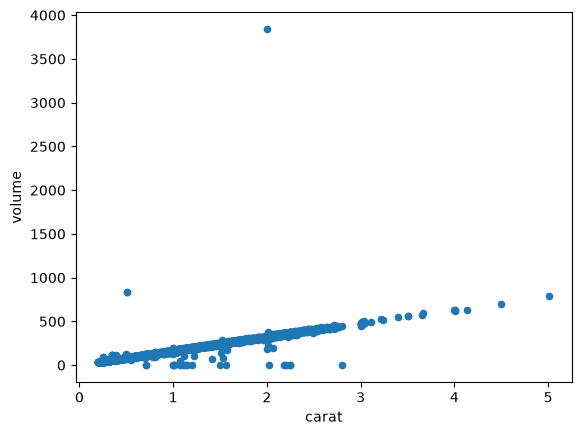

In [17]:
diamonds.plot.scatter(x='carat', y='volume')
plt.show()

### Task 2

Create a new dataframe `diamonds1` that excludes the outliers, i.e. where `volume` is between $20$ and $800$ exclusive. 

Then create a scatter plot with the new dataframe using the same variables as above.

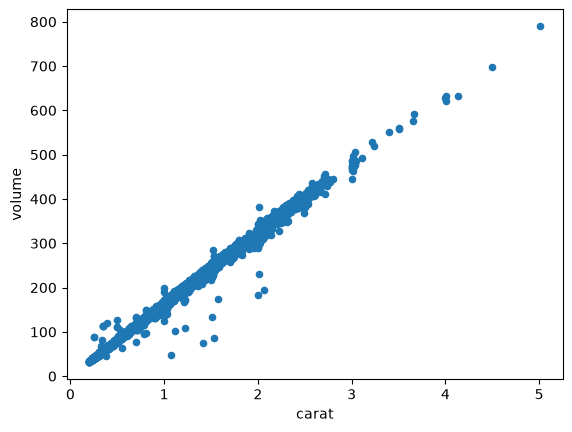

In [18]:
diamonds1 = diamonds.query("volume > 20 and volume < 800")
diamonds1.plot.scatter(x='carat', y='volume')
plt.show()

### Task 3 

Create a scatter matrix from `diamonds1`.

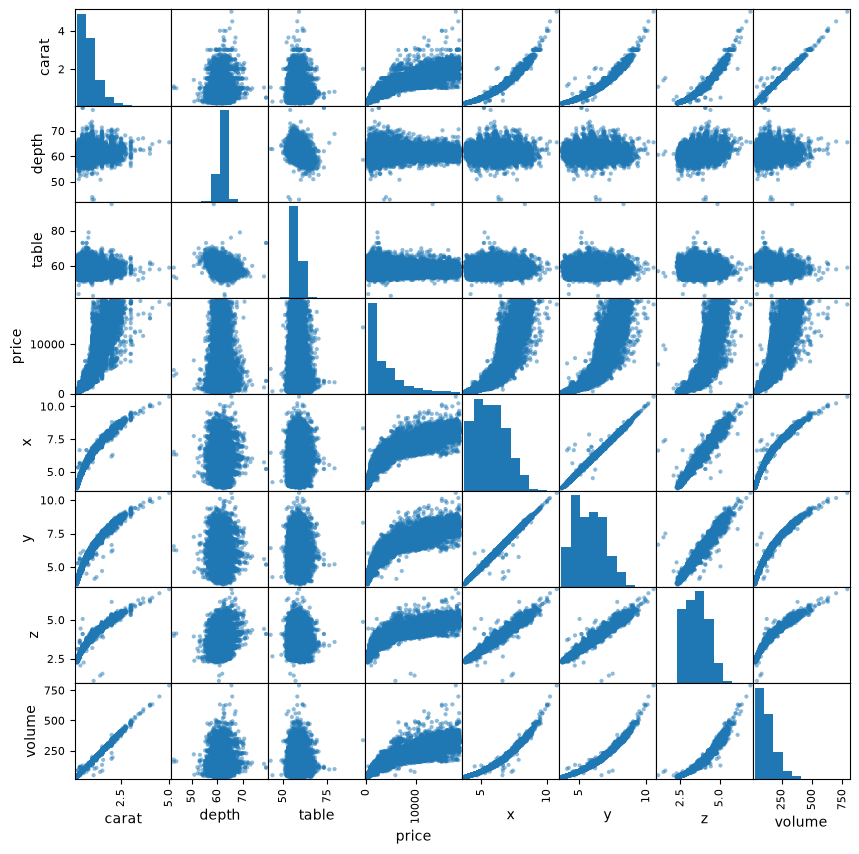

In [19]:
pd.plotting.scatter_matrix(diamonds1, figsize=(10,10))
plt.show()

### Task 4

Create a scatter plot of `carat` versus `price`. 

Set the color to `cut` and make the figure size $12$ by $10$.


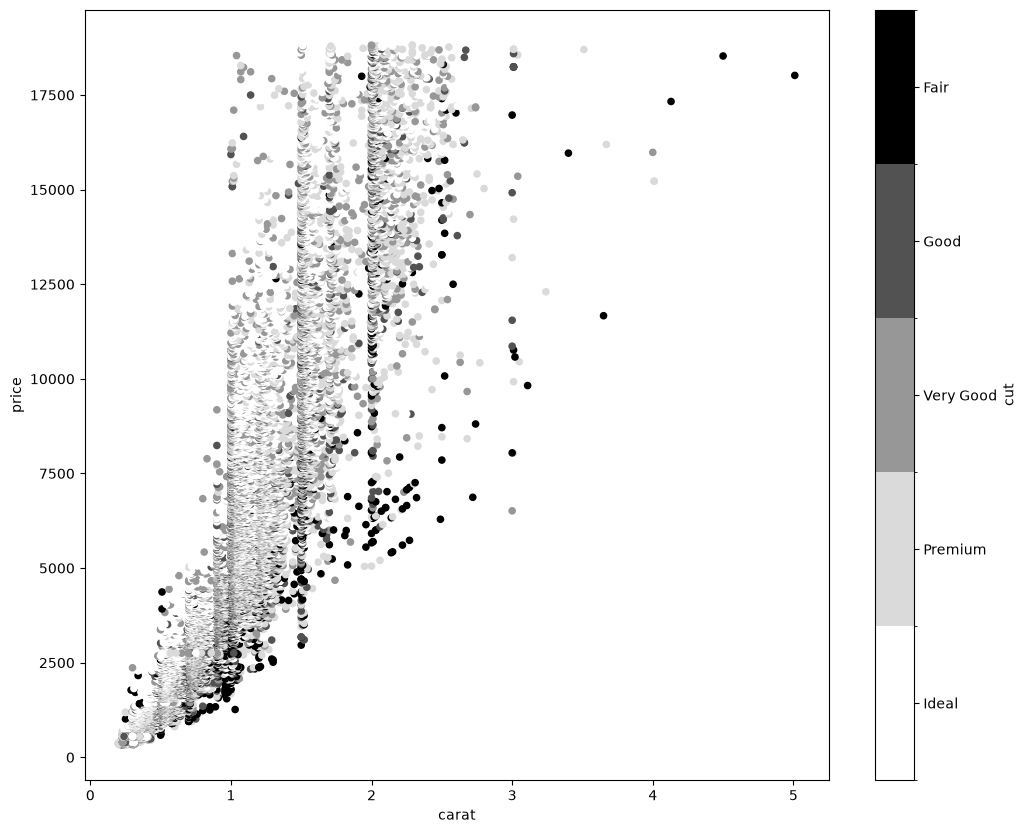

In [20]:
diamonds1.plot.scatter(x="carat", y="price", c='cut', figsize=(12,10))
plt.show()

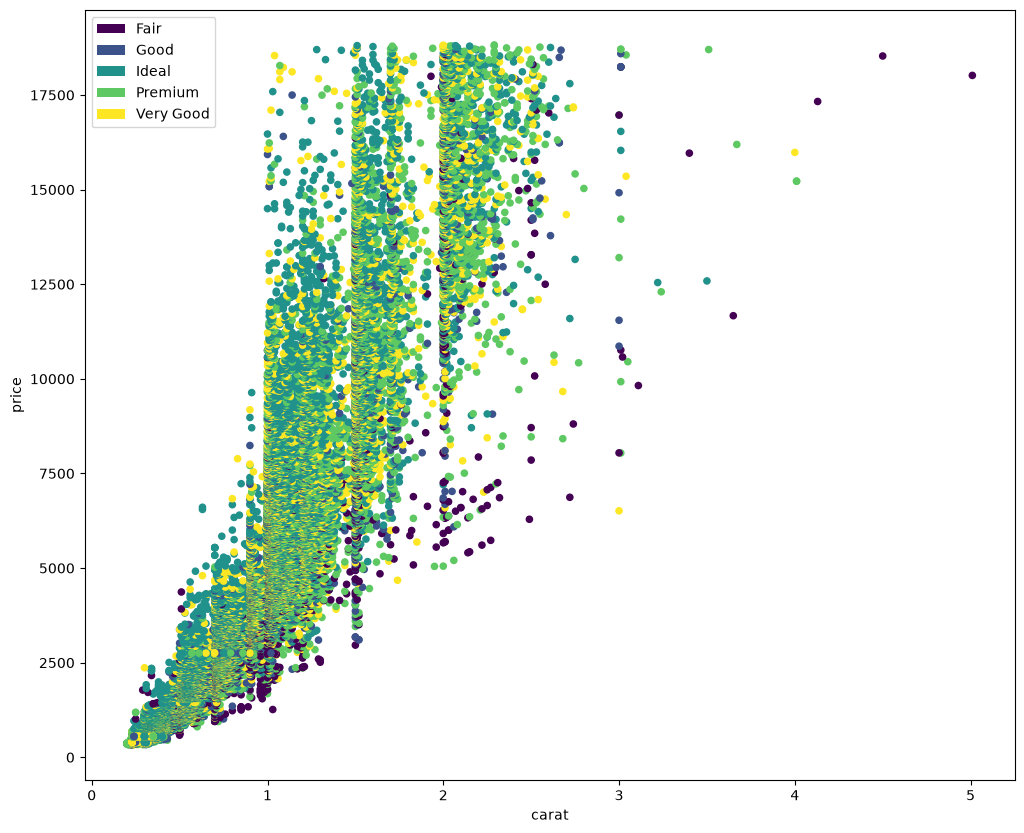

In [21]:
diamonds1['cut'] = diamonds1['cut'].astype('str')
diamonds1.plot.scatter(x="carat", y="price", c='cut', figsize=(12,10))
plt.show()

### Task 5 

Create a hexbin plot of `carat` versus `price`.

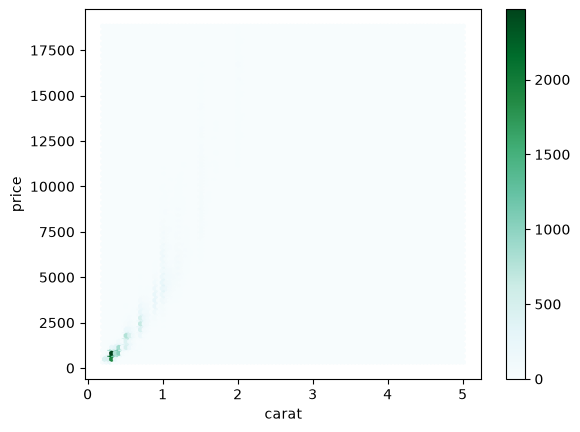

In [22]:
diamonds1.plot.hexbin(x="carat", y="price")
plt.show()

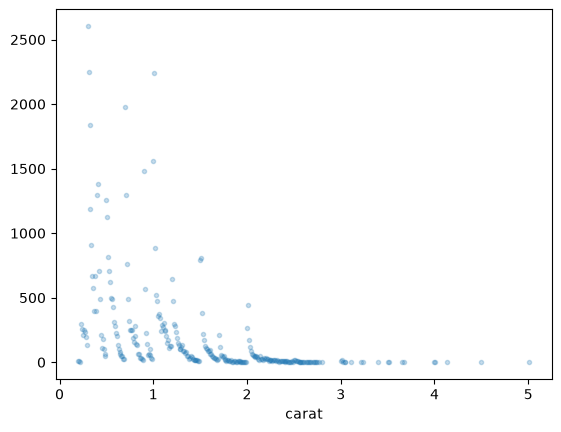

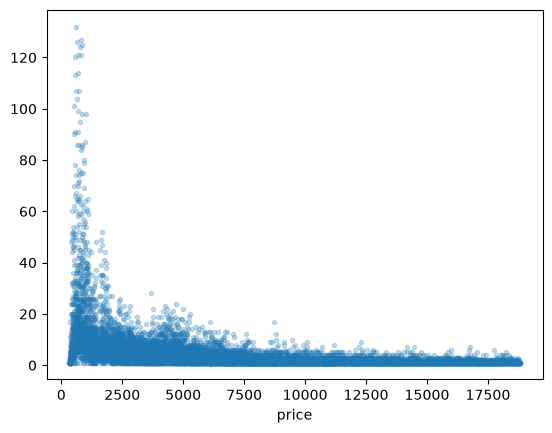

In [43]:
diamonds1.carat.value_counts().sort_index().plot(style='.', alpha=.25)
plt.show()
diamonds1.price.value_counts().sort_index().plot(style='.', alpha=.25)
plt.show()